# Práctica 1. Representación y medida de un qubit

**Asignatura:** Computación Cuántica  
**Tema 1:** Conceptos fundamentales. Superposición cuántica  
**Duración estimada:** 45-55 minutos  
**Modalidad:** Individual o por parejas

En esta práctica representaremos estados de un qubit mediante vectores complejos, comprobaremos su normalización, aplicaremos la regla de Born y simularemos medidas en la base computacional. No utilizaremos Qiskit: trabajaremos directamente con el formalismo matemático mediante NumPy.

## Objetivos

Al finalizar la práctica serás capaz de:

- Representar estados de un qubit como vectores complejos.
- Validar y normalizar vectores de estado.
- Calcular probabilidades mediante la regla de Born.
- Simular una o varias medidas en la base computacional.
- Comparar probabilidades teóricas y frecuencias experimentales.
- Analizar el efecto del número de *shots*.
- Identificar estados diferentes que producen el mismo histograma en una base concreta.

> Completa todas las celdas marcadas con `TODO` y responde en Markdown a las preguntas planteadas.

In [122]:
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 42
rng = np.random.default_rng(SEMILLA)

np.set_printoptions(precision=5, suppress=True)

## Parte A. Representación de estados

### Ejercicio 1. Base computacional

Representa los estados

$$|0\rangle=\begin{pmatrix}1\\0\end{pmatrix},\qquad |1\rangle=\begin{pmatrix}0\\1\end{pmatrix}.$$

Muestra los vectores, su forma, el tipo de sus componentes y su norma.

In [123]:
# TODO: crea los estados con dtype=complex
# Al ser complejo es muy importante definir el tipo de dato para que no se pierda la parte imaginaria/complejo
ket_0 = np.array([1,0], dtype=complex)
ket_1 = np.array([0,1], dtype=complex)

# TODO: muestra vector, shape, dtype y norma de cada estado
print("Estado |0⟩:")
print("Vector:", ket_0)
print("Forma:", ket_0.shape)
print("Tipo:", ket_0.dtype)
print("Norma:", np.linalg.norm(ket_0))

print("\nEstado |1⟩:")
print("Vector:", ket_1)
print("Forma:", ket_1.shape)
print("Tipo:", ket_1.dtype)
print("Norma:", np.linalg.norm(ket_1))

# Es para verificar que los estados están normalizados, es decir, que su norma es 1.0 con cierta tolerancia por si acaso por error de precición de máquina no da exactamente 1 pero en realidad si está normalizado. 
print(np.isclose(np.linalg.norm(ket_0), 1.0, atol=1e-10))
print(np.isclose(np.linalg.norm(ket_1), 1.0, atol=1e-10))


Estado |0⟩:
Vector: [1.+0.j 0.+0.j]
Forma: (2,)
Tipo: complex128
Norma: 1.0

Estado |1⟩:
Vector: [0.+0.j 1.+0.j]
Forma: (2,)
Tipo: complex128
Norma: 1.0
True
True


**Responde:**

1. ¿Por qué los arrays deben admitir números complejos?

    _Los qubit tienen una parte imaginaria, sus amplitudes, por lo que el array hay que asegurarse que admitan está parte para que al hacer las operaciones den bien los resultados y no de errores._


2. ¿Qué dimensión tiene el espacio de estados de un qubit?

    _Tiene dos dimensiones porque admite 2 estado_


3. ¿Qué valor debe tener la norma de un estado válido?

    _Si el estado está normalizado (que es como debería de estar), la norma es 1_


### Ejercicio 2. Superposiciones

Representa los siguientes estados y, para cada uno, muestra el vector, sus amplitudes, su norma y si está normalizado:

$$|\psi_1\rangle=\frac{|0\rangle+|1\rangle}{\sqrt{2}}$$

$$|\psi_2\rangle=\frac{\sqrt{3}}{2}|0\rangle+\frac{1}{2}|1\rangle$$

$$|\psi_3\rangle=\frac{1}{\sqrt{2}}|0\rangle+\frac{i}{\sqrt{2}}|1\rangle$$

$$|\psi_4\rangle=\frac{1+i}{2}|0\rangle+\frac{1-i}{2}|1\rangle.$$

In [124]:
# TODO: representa los cuatro estados
psi_1 = np.array([1/np.sqrt(2), 1/np.sqrt(2)], dtype=complex)
psi_2 = np.array([np.sqrt(3)/2, 1/2], dtype=complex)
psi_3 = np.array([1/np.sqrt(2), 1j/np.sqrt(2)], dtype=complex)
psi_4 = np.array([(1+1j)/2, (1-1j)/2], dtype=complex)

estados = {
    "psi_1": psi_1,
    "psi_2": psi_2,
    "psi_3": psi_3,
    "psi_4": psi_4,
}

# TODO: recorre el diccionario y muestra los datos solicitados
# Usa np.isclose para comprobar la normalización
for nombre, estado in estados.items():
    print(f"\nEstado {nombre}:")
    print("Vector:", estado)
    print("Forma:", estado.shape)
    print("Norma:", f"{np.linalg.norm(estado):3f}")
    print("Normalizado:", np.isclose(np.linalg.norm(estado), 1.0, atol=1e-10))


Estado psi_1:
Vector: [0.70711+0.j 0.70711+0.j]
Forma: (2,)
Norma: 1.000000
Normalizado: True

Estado psi_2:
Vector: [0.86603+0.j 0.5    +0.j]
Forma: (2,)
Norma: 1.000000
Normalizado: True

Estado psi_3:
Vector: [0.70711+0.j      0.     +0.70711j]
Forma: (2,)
Norma: 1.000000
Normalizado: True

Estado psi_4:
Vector: [0.5+0.5j 0.5-0.5j]
Forma: (2,)
Norma: 1.000000
Normalizado: True


**Responde:**

1. ¿Por qué no conviene comprobar números en coma flotante con `valor == 1.0`?

    _Porque a veces por limitaciones de computo, un valor en papel es exácto pero al calcularlo por ordenador es un número decimal periodico. Al hacer `valor == 1.0`, el resultado es `Falso` si el valor es `valor= 0.999999...`_
2. ¿Puede un estado válido contener amplitudes imaginarias?

    _Sí_ 
3. ¿Implica una amplitud imaginaria que la probabilidad sea imaginaria?

    _No, la probailidad es el módulo al cuadrado por lo que siempre será real._ 



## Parte B. Validación y normalización

### Ejercicio 3. Validación de estados

Completa una función que verifique que la entrada tiene dos amplitudes, contiene valores finitos y posee norma uno. El vector nulo y los vectores con otra dimensión no son estados válidos de un qubit.

In [125]:
def es_estado_valido(estado, tolerancia=1e-10):
    """Devuelve True si estado representa un estado válido de un qubit."""
    # TODO
    
    try:
        vector= np.array(estado, dtype=complex)
    except (ValueError, TypeError):
        return False, "El estado no se puede convertir en un array de tipo complejo."
    
    # np.all lo que se escribe se aplica a todos los elementos. 
    if not np.all(np.isfinite(vector)):
        return False, "El estado contiene valores no finitos (NaN o Inf)."

    if vector.shape != (2,):
        return False, f"El estado no tiene la dimensión correcta (debe ser un vector de 2 elementos). Tiene la forma {vector.shape}."
    normal = np.linalg.norm(vector)

    if not np.isclose(normal, 1.0, atol=tolerancia):
        return False, f"El estado no está normalizado. La norma es {normal}."
   
    return True, "El estado es válido."

casos = {
    "ket_0": [1, 0],
    "ket_1": [0, 1],
    "equilibrado": [1 / np.sqrt(2), 1 / np.sqrt(2)],
    "no_normalizado": [1, 1],
    "vector_nulo": [0, 0],
    "dimension_incorrecta": [1, 0, 0],
    "con_nan": [np.nan, 0],
}

# TODO: muestra si cada caso es válido y justifica brevemente el resultado
for nombre, estado in casos.items():
    valido, mensaje = es_estado_valido(estado)
    print(f"\nCaso '{nombre}':\t""Estado:", estado)
    # print("Estado:", estado)
    print("Válido:", valido, "\tMensaje:", mensaje)



Caso 'ket_0':	Estado: [1, 0]
Válido: True 	Mensaje: El estado es válido.

Caso 'ket_1':	Estado: [0, 1]
Válido: True 	Mensaje: El estado es válido.

Caso 'equilibrado':	Estado: [np.float64(0.7071067811865475), np.float64(0.7071067811865475)]
Válido: True 	Mensaje: El estado es válido.

Caso 'no_normalizado':	Estado: [1, 1]
Válido: False 	Mensaje: El estado no está normalizado. La norma es 1.4142135623730951.

Caso 'vector_nulo':	Estado: [0, 0]
Válido: False 	Mensaje: El estado no está normalizado. La norma es 0.0.

Caso 'dimension_incorrecta':	Estado: [1, 0, 0]
Válido: False 	Mensaje: El estado no tiene la dimensión correcta (debe ser un vector de 2 elementos). Tiene la forma (3,).

Caso 'con_nan':	Estado: [nan, 0]
Válido: False 	Mensaje: El estado contiene valores no finitos (NaN o Inf).


### Ejercicio 4. Normalización

Completa la función. Debe convertir la entrada a un array complejo, comprobar su dimensión y finitud, rechazar el vector nulo y devolver un vector de norma uno.

In [126]:
def normalizar_estado(estado):
    """Normaliza un vector de dos amplitudes complejas."""
    try:
        vector = np.array(estado, dtype=complex)
    except (ValueError, TypeError):
        raise ValueError("El estado no se puede convertir en un array de tipo complejo.")

    if vector.shape != (2,):
        raise ValueError(f"El estado no tiene la dimensión correcta (debe ser un vector de 2 elementos). Tiene la forma {vector.shape}.")

    
    if not np.all(np.isfinite(vector)):
        raise ValueError("El estado contiene valores no finitos (NaN o Inf).")

    norma = np.linalg.norm(vector)
    if np.isclose(norma, 0.0, atol=1e-10):
        raise ValueError("El estado es el vector nulo y no se puede normalizar.")

    return vector / norma



vectores = [
    np.array([1, 1], dtype=complex),
    np.array([3, 4], dtype=complex),
    np.array([1 + 1j, 2 - 1j], dtype=complex),
]

# TODO: muestra vector y norma antes y después de normalizar
for i, vector in enumerate(vectores):
    print(f"\nVector {i + 1}:")
    print("Antes de normalizar:", vector)
    print("Norma antes de normalizar:", np.linalg.norm(vector))
    try:
        vector_normalizado = normalizar_estado(vector)
        print("Después de normalizar:", vector_normalizado)
        print("Norma después de normalizar:", np.linalg.norm(vector_normalizado))
    except ValueError as e:
        print("Error al normalizar:", e)


Vector 1:
Antes de normalizar: [1.+0.j 1.+0.j]
Norma antes de normalizar: 1.4142135623730951
Después de normalizar: [0.70711+0.j 0.70711+0.j]
Norma después de normalizar: 0.9999999999999999

Vector 2:
Antes de normalizar: [3.+0.j 4.+0.j]
Norma antes de normalizar: 5.0
Después de normalizar: [0.6+0.j 0.8+0.j]
Norma después de normalizar: 1.0

Vector 3:
Antes de normalizar: [1.+1.j 2.-1.j]
Norma antes de normalizar: 2.6457513110645907
Después de normalizar: [0.37796+0.37796j 0.75593-0.37796j]
Norma después de normalizar: 0.9999999999999999


**Responde:**

1. ¿Cambia la dirección del vector al normalizarlo?

    _No, normalizar solo cambia la longitud del vector, no su dirección_
2. ¿Qué ocurre con la relación entre sus componentes?

    _Al normalizar cambia el número pero no la proporción entre ellos. Las amplitudes normalizadas seguirán dando las probabilidades y la fase._
3. ¿Por qué no puede normalizarse el vector nulo?

    _Porque su norma es 0 y al dividir entre 0 que daría una inderteminación_



## Parte C. Regla de Born

### Ejercicio 5. Probabilidades de medida

Para $|\psi\rangle=\alpha|0\rangle+\beta|1\rangle$, la regla de Born establece $P(0)=|\alpha|^2$ y $P(1)=|\beta|^2$. Completa la función sin utilizar `estado ** 2`.

In [127]:
def calcular_probabilidades(estado):
    """Devuelve {0: P(0), 1: P(1)} para un estado válido."""
    valido, mensaje = es_estado_valido(estado)
    if not valido:
        raise ValueError(f"Estado no válido: {mensaje}")

    vector = np.array(estado, dtype=complex)
    P_0 = np.abs(vector[0]) ** 2
    P_1 = np.abs(vector[1]) ** 2
    return {0: float(P_0), 1: float(P_1)}

estados= {
    "ket_0": ket_0,
    "ket_1": ket_1,
    "psi_1": psi_1,
    "psi_2": psi_2
}

# TODO: aplica la función a ket_0, ket_1 y psi_1...psi_4
# Comprueba en todos los casos que P(0) + P(1) = 1
for nombre, estado in estados.items():
    probabilidades = calcular_probabilidades(estado)
    suma_probabilidades = probabilidades[0] + probabilidades[1]
    print(f"\nEstado {nombre}:")
    print("Probabilidades:", probabilidades)
    print("Suma de probabilidades:", suma_probabilidades)
    print("¿Suma es 1?", np.isclose(suma_probabilidades, 1.0, atol=1e-10))


Estado ket_0:
Probabilidades: {0: 1.0, 1: 0.0}
Suma de probabilidades: 1.0
¿Suma es 1? True

Estado ket_1:
Probabilidades: {0: 0.0, 1: 1.0}
Suma de probabilidades: 1.0
¿Suma es 1? True

Estado psi_1:
Probabilidades: {0: 0.4999999999999999, 1: 0.4999999999999999}
Suma de probabilidades: 0.9999999999999998
¿Suma es 1? True

Estado psi_2:
Probabilidades: {0: 0.7499999999999999, 1: 0.25}
Suma de probabilidades: 0.9999999999999999
¿Suma es 1? True


### Ejercicio 6. Cálculo manual con amplitudes complejas

Considera

$$|\psi\rangle=\frac{1+i}{2}|0\rangle+\frac{1-i}{2}|1\rangle.$$

Calcula manualmente $\alpha$, $\beta$, $|\alpha|^2$, $|\beta|^2$, $P(0)$ y $P(1)$. Después compruébalo con la función anterior.

**Desarrollo y respuesta:** 
$$\begin{align}
& \alpha = \frac{1+i}{2} \qquad  |\alpha|^2 = \alpha^*\alpha = \frac{(1-i)(1+i)}{4} = \frac{1 - i^2}{4} = \frac{1+1}{4} = \frac{1}{2}\\
&\beta = \frac{1-i}{2} \qquad |\beta|^2 = \beta^*\beta = \frac{(1+i)(1-i)}{4} = \frac{2}{4} = \frac{1}{2}\\
& \text{Normalizado (?): } = |\alpha|^2 + |\beta|^2 = \frac12 + \frac12 = 1\\
&P(0) = |\alpha|^2 = \frac12 \qquad P(1) = |\beta|^2 = \frac12 
\end{align}$$

In [128]:
# TODO: comprobación computacional del ejercicio 6
Psi_ket= np.array([(1+1j)/2, (1-1j)/2], dtype=complex)
probabilidades_Psi_ket = calcular_probabilidades(Psi_ket)
print("Probabilidades para |Ψ⟩:", probabilidades_Psi_ket)
alpha= Psi_ket[0]
beta= Psi_ket[1]
print("Alpha:", alpha, "|alpha|² =", abs(alpha)**2)
print("Beta:", beta, "|beta|² =", abs(beta)**2)


Probabilidades para |Ψ⟩: {0: 0.5000000000000001, 1: 0.5000000000000001}
Alpha: (0.5+0.5j) |alpha|² = 0.5000000000000001
Beta: (0.5-0.5j) |beta|² = 0.5000000000000001


## Parte D. Simulación de la medida

### Ejercicio 7. Una medida

Completa la función para simular una medida en la base computacional. Debe devolver el entero 0 o 1 de acuerdo con las probabilidades del estado.

In [129]:
def medir(estado, rng=None):
    """Simula una medida del qubit en la base computacional."""

    if rng is None:
       rng = np.random.default_rng(SEMILLA)
    estado= normalizar_estado(estado)  # Asegurarse de que el estado esté normalizado
    # Calcular probabilidades
    probabilidades = calcular_probabilidades(estado)
    # Elegir un resultado según las probabilidades
    resultado = rng.choice([0, 1], p=[probabilidades[0], probabilidades[1]])
    return resultado


a= np.array([(1+1j)/2, (1-1j)/2], dtype=complex)
#  mide ket_0, ket_1, psi_1 y psi_2
for nombre, estado in estados.items():
    m = medir(estado)
    print(f"Medición del estado {nombre}: {m}")


Medición del estado ket_0: 0
Medición del estado ket_1: 1
Medición del estado psi_1: 1
Medición del estado psi_2: 1


**Responde:**

1. ¿Qué debe producir siempre $|0\rangle$? ¿Y $|1\rangle$?

    _El esatdo $|0\rangle$ simpre produce 0 con una probabilidad del 100%, y $|1\rangle$ siempre produce 1 con una probabilidad de 100%_
2. ¿Permite una medida aislada conocer $\alpha$ y $\beta$?

    _No, al colapsar se hace imposible saber el estado antes de obtener el resultado_
3. Si obtenemos 0, ¿podemos afirmar que el estado inicial era $|0\rangle$?
    
    _No_

### Ejercicio 8. Medidas repetidas

Cada *shot* representa una nueva preparación del mismo estado seguida de una medida. La función debe rechazar valores de `shots` que no sean enteros positivos.

In [130]:
# def medir_repetidamente(estado, shots=1000, semilla=None):
#     """Devuelve {0: número de ceros, 1: número de unos}."""
#     if semilla is not None:
#         rng = np.random.default_rng(semilla)
#     else:
#         rng = np.random.default_rng(SEMILLA)
    
#     conteos = {0: 0, 1: 0}
#     for _ in range(shots):
#         resultado = medir(estado, rng)
#         # conteo= np.bicount(resultado, minlength=2)  # Esto no es necesario, ya que solo hay dos posibles resultados (0 y 1)
#         conteos[resultado] += 1
#     return conteos

def medir_repetidamente(estado, shots=1000, semilla=None):
    """Devuelve {0: número de ceros, 1: número de unos}."""
    if isinstance(shots, bool) or not isinstance(shots, (int, np.integer)) or shots <= 0:
        raise ValueError("El número de shots debe ser un entero positivo.")

    rng = np.random.default_rng(semilla)
    probs = calcular_probabilidades(estado)
    resultados = rng.choice([0, 1], size=shots, p=[probs[0], probs[1]])
    conteos = np.bincount(resultados, minlength=2)
    return {0: int(conteos[0]), 1: int(conteos[1])}




shots_estudiados = [10, 100, 1_000, 10_000, 100_000]
resultados_experimento = []

# for n in shots_estudiados:
    # conteos = medir_repetidamente(psi_2, shots=n, semilla=SEMILLA)
    # print(f"\nResultados para {n} shots:")
    # print(f"Conteos: {conteos}")

# TODO: experimenta con psi_2 y calcula conteos, frecuencias y errores absolutos
# Guarda una fila por número de shots en resultados_experimento
for shots in shots_estudiados:
    conteos = medir_repetidamente(psi_2, shots=shots, semilla=SEMILLA)
    frecuencia_0 = conteos[0] / shots
    frecuencia_1 = conteos[1] / shots
    error_absoluto_0 = abs(frecuencia_0 - calcular_probabilidades(psi_2)[0])
    error_absoluto_1 = abs(frecuencia_1 - calcular_probabilidades(psi_2)[1])
    
    resultados_experimento.append({
        "shots": shots,
        "conteos": conteos,
        "frecuencia_0": frecuencia_0,
        "frecuencia_1": frecuencia_1,
        "error_absoluto_0": error_absoluto_0,
        "error_absoluto_1": error_absoluto_1
    })
    print(f"\nResultados para {shots} shots:")
    print(f"Conteos: {conteos}\tFrecuencia de 0: {frecuencia_0}\tFrecuencia de 1: {frecuencia_1}\t Error absoluto de 0: {error_absoluto_0}\t Error absoluto de 1: {error_absoluto_1}")


Resultados para 10 shots:
Conteos: {0: 5, 1: 5}	Frecuencia de 0: 0.5	Frecuencia de 1: 0.5	 Error absoluto de 0: 0.2499999999999999	 Error absoluto de 1: 0.25

Resultados para 100 shots:
Conteos: {0: 77, 1: 23}	Frecuencia de 0: 0.77	Frecuencia de 1: 0.23	 Error absoluto de 0: 0.02000000000000013	 Error absoluto de 1: 0.01999999999999999

Resultados para 1000 shots:
Conteos: {0: 743, 1: 257}	Frecuencia de 0: 0.743	Frecuencia de 1: 0.257	 Error absoluto de 0: 0.006999999999999895	 Error absoluto de 1: 0.007000000000000006

Resultados para 10000 shots:
Conteos: {0: 7558, 1: 2442}	Frecuencia de 0: 0.7558	Frecuencia de 1: 0.2442	 Error absoluto de 0: 0.005800000000000138	 Error absoluto de 1: 0.0058

Resultados para 100000 shots:
Conteos: {0: 75035, 1: 24965}	Frecuencia de 0: 0.75035	Frecuencia de 1: 0.24965	 Error absoluto de 0: 0.0003500000000000725	 Error absoluto de 1: 0.0003499999999999892


Completa la tabla con tus resultados:

| Shots | $N(0)$ | $N(1)$ | $f(0)$ | $f(1)$ | $E_0$ | $E_1$ |
|---:|---:|---:|---:|---:|---:|---:|
| 10 | 5 | 5 | 0.5 | 0.5 | 0.25 | 0.25|
| 100 | 77 | 23 | 0.77 | 0.23 | 0.02 | 0.02|
| 1.000 | 743 | 257 | 0.743 | 0.257 | 0.007 | 0.007 |
| 10.000 | 7558 | 2442 | 0.7558 | 0.2442 | 0.0058 | 0.0058 |
| 100.000 | 75035 | 24965 | 0.75035 | 0.24965 | 0.00035 | 0.00035 |

**Responde:** ¿Coinciden exactamente frecuencias y probabilidades? ¿Qué ocurre al aumentar los shots? ¿Debe disminuir el error de forma estrictamente monótona? ¿Se mide repetidamente el mismo qubit después de su colapso?

**Respuesta:** Por lo general si que hay una mejoría en relación con los shots, menos en los casos de 50/50 que no aparece una mejoría notoria al aumentar los shot. 

Al aumentar los shots es repetir las mismas conciones con diferentes qubit con el mismo estado y al colapsar la proporcionalidad de resultados muestra las amplitudes. Al aumentar los shots las frecuencias se acercan a las probabilidades (ley de los grandes números). 

## Parte E. Visualización

### Ejercicio 9. Convergencia de la frecuencia

Representa la frecuencia experimental de obtener 0 frente al número de shots. Añade una línea horizontal para la probabilidad teórica $P(0)=0{,}75$ y usa escala logarítmica en el eje horizontal. Incluye título, etiquetas, leyenda y cuadrícula.

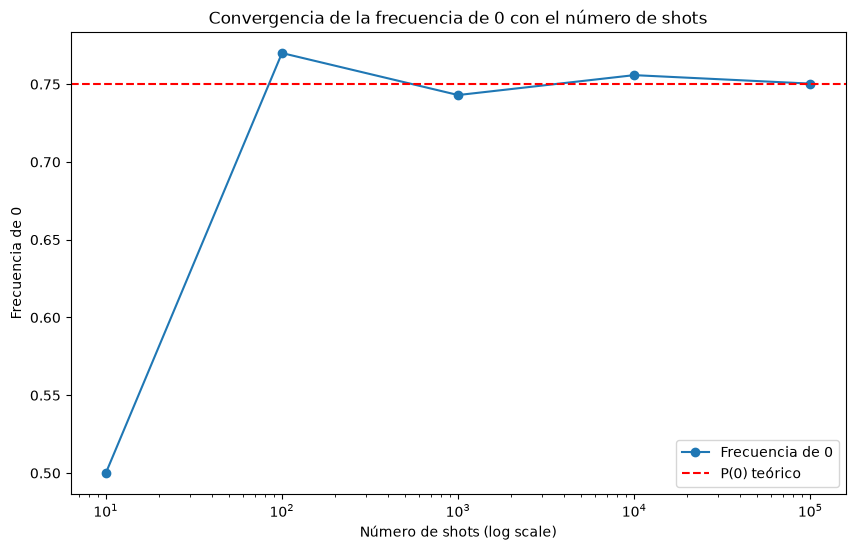

In [131]:
# TODO: representa la convergencia de f(0)
# Sugerencia: plt.xscale("log")
plt.figure(figsize=(10, 6))
shots = np.array([resultado["shots"] for resultado in resultados_experimento])
frecuencias_0 = np.array([resultado["frecuencia_0"] for resultado in resultados_experimento])
plt.plot(shots, frecuencias_0, marker='o', label='Frecuencia de 0')
plt.xscale("log")
plt.xlabel("Número de shots (log scale)")
plt.ylabel("Frecuencia de 0")
plt.title("Convergencia de la frecuencia de 0 con el número de shots")
plt.axhline(y=calcular_probabilidades(psi_2)[0], color='r', linestyle='--', label='P(0) teórico')
plt.legend()

**Interpretación de la gráfica (4-6 líneas):** 
la gráfica muestra la probabilidad de que salga 0 en diferentes numeros de shots. La linea roja muestra la probabilidad real. Se observa que a medida que aumenta el número de shots, la cuva se aproxima a la línea roja. Osea, la aproximación es más precisa. 

### Ejercicio 10. Histograma de resultados

Para 1.000 shots, representa un diagrama de barras con los conteos de 0 y 1. Añade el valor numérico sobre cada barra.

C:\Users\Usuario\AppData\Local\Temp\ipykernel_15412\2122609300.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


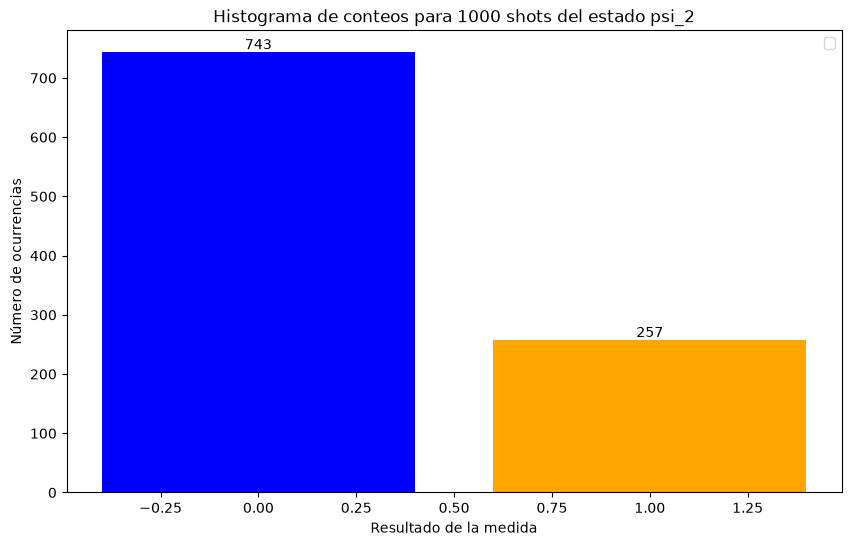

In [132]:
# TODO: representa el histograma de conteos
plt.figure(figsize=(10, 6))
# Tomamos los conteos del último experimento (100,000 shots)
conteos_100= medir_repetidamente(psi_2, shots=1000, semilla=SEMILLA)


barra= plt.bar( conteos_100.keys(), conteos_100.values(), color=['blue', 'orange'])
plt.bar_label(barra, label_type='edge')
plt.xlabel("Resultado de la medida")
plt.ylabel("Número de ocurrencias")
plt.title("Histograma de conteos para 1000 shots del estado psi_2")
plt.legend()
plt.show()




**Responde:** ¿Qué información muestra el histograma? ¿Muestra directamente las amplitudes? ¿Permite determinar la fase relativa?

**Respuesta:** El histograma muestra las veces que se obtivo cada resultado clásico en 1000 shots. Esto mostraría las probabilidades aproximadas de $|\alpha|^2$ y $|\beta|^2$. no muestra las amplitudes. 

## Parte F. Estados con las mismas probabilidades

### Ejercicio 11. El papel de la fase

Compara los estados

$$|\psi_A\rangle=\frac{|0\rangle+|1\rangle}{\sqrt{2}},\qquad |\psi_B\rangle=\frac{|0\rangle-|1\rangle}{\sqrt{2}},\qquad |\psi_C\rangle=\frac{|0\rangle+i|1\rangle}{\sqrt{2}}.$$

Represéntalos, valida su normalización, calcula sus probabilidades y simula 10.000 medidas de cada uno.


Estado psi_A:
Vector: [0.70711+0.j 0.70711+0.j]
Probabilidades: O : 0.4999999999999999 , 1 : 0.4999999999999999
Conteos: {0: 503, 1: 497}

Estado psi_B:
Vector: [ 0.70711+0.j -0.70711+0.j]
Probabilidades: O : 0.4999999999999999 , 1 : 0.4999999999999999
Conteos: {0: 503, 1: 497}

Estado psi_C:
Vector: [0.70711+0.j      0.     +0.70711j]
Probabilidades: O : 0.4999999999999999 , 1 : 0.4999999999999999
Conteos: {0: 503, 1: 497}

¿psi_A == psi_B? False
¿psi_A == psi_C? False
¿psi_B == psi_C? False


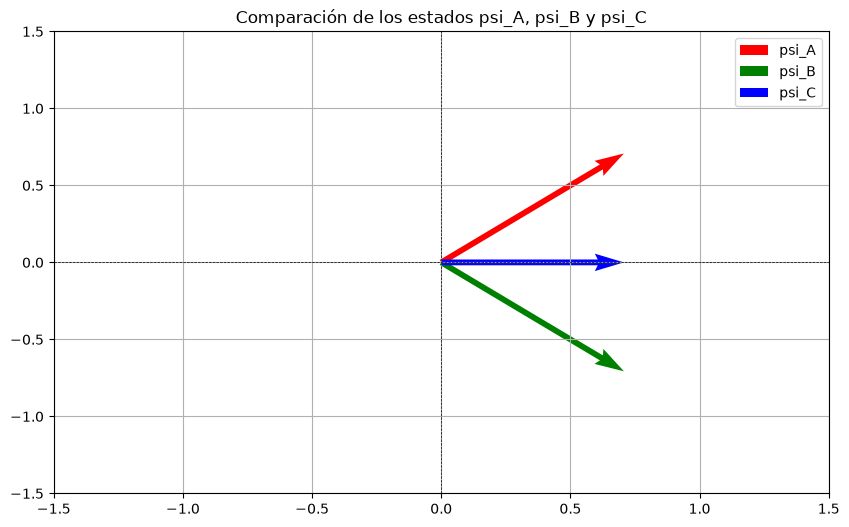

In [133]:
# TODO: representa y compara psi_A, psi_B y psi_C
psi_A = np.array([1, 1], dtype=complex) / np.sqrt(2)
psi_B = np.array([1, -1], dtype=complex) / np.sqrt(2)
psi_C = np.array([1, 1j], dtype=complex) / np.sqrt(2)

estados_comparacion = {
    "psi_A": psi_A,
    "psi_B": psi_B,
    "psi_C": psi_C,
}
conteos_estados= {}

for nombre, estado in estados_comparacion.items():
    valido, mensaje = es_estado_valido(estado)
    if not valido:
        print(f"Estado {nombre} no válido: {mensaje}")
        continue
    probabilidades = calcular_probabilidades(estado)
    conteos = medir_repetidamente(estado, shots=1000, semilla=SEMILLA)
    conteos_estados[nombre] = conteos
    print(f"\nEstado {nombre}:")
    print("Vector:", estado)
    print("Probabilidades: O :", probabilidades[0], ", 1 :", probabilidades[1])
    print(f"Conteos: {conteos}")

print("\n¿psi_A == psi_B?", np.allclose(psi_A, psi_B))
print("¿psi_A == psi_C?", np.allclose(psi_A, psi_C))
print("¿psi_B == psi_C?", np.allclose(psi_B, psi_C))

plt.figure(figsize=(10, 6))
# Representar psi_A
plt.quiver(0, 0, psi_A[0].real, psi_A[1].real, angles='xy', scale_units='xy', scale=1, color='r', label='psi_A')
plt.quiver(0, 0, psi_B[0].real, psi_B[1].real, angles='xy', scale_units='xy', scale=1, color='g', label='psi_B')
plt.quiver(0, 0, psi_C[0].real, psi_C[1].real, angles='xy', scale_units='xy', scale=1, color='b', label='psi_C')
plt.xlim(-1.5, 1.5)
plt.ylim(-1.5, 1.5)
plt.axhline(0, color='black', linewidth=0.5, linestyle='--')
plt.axvline(0, color='black', linewidth=0.5, linestyle='--')
plt.grid()
plt.title("Comparación de los estados psi_A, psi_B y psi_C")
plt.legend()
plt.show()




**Responde:**

1. ¿Son iguales los tres vectores?

    _No, son vectores distintos_
2. ¿Producen las mismas probabilidades en la base computacional?

    _Si_
3. ¿Podemos concluir que representan el mismo estado?

    _No, aunque el resultado de de la probabilidad sea el mismo, las fases son distintas por lo que no es el mismo estado_
4. ¿Permite esta medida detectar sus diferencias?

    _No, la medida solo expresa la probibilidad que es el módulo al cuadrado por lo que la parte imaginaria y los valores negativos que hacen que sean diferentes se pierde._
5. ¿Qué información no aparece en los histogramas?

    _La fase_
6. ¿Qué fenómeno permitirá aprovechar posteriormente estas diferencias?

    _La interferencia. Al añadir otra puerta o miediendo en otr base, la fase relativa se convierte en diferentes probabilidades_



### Ejercicio 12. Fase global y fase relativa

Compara

$$|\phi_A\rangle=\frac{1}{\sqrt{2}}\begin{pmatrix}1\\1\end{pmatrix},\quad |\phi_B\rangle=-\frac{1}{\sqrt{2}}\begin{pmatrix}1\\1\end{pmatrix},\quad |\phi_C\rangle=\frac{1}{\sqrt{2}}\begin{pmatrix}1\\-1\end{pmatrix}.$$

¿Qué estados se diferencian solo por una fase global? ¿Dónde hay una diferencia de fase relativa? ¿Cuáles son físicamente equivalentes?

**Respuesta razonada:** 
- En $\ket{\phi_A}$ y $\ket{\phi_B}$ solo se diferencian en una fase global de -1, que multiplica a todas las amplitudes por igual. Al medirlo da la misma probabilidad, asi que físicamente equivalentes. 

- En $\ket{\phi_A}$ y $\ket{\phi_C}$ hay una diferencia de fase relativa al igual que en $\ket{\phi_C}$ y $\ket{\phi_B}$. En este caso son las estados positivos y negativos. 

## Parte G. Construcción segura de estados

### Ejercicio 13. Función de construcción

Completa una función que acepte amplitudes reales o complejas, rechace valores no finitos y el vector nulo, y devuelva el estado normalizado.

In [134]:
def crear_estado(alpha, beta):
    """Construye y normaliza el estado de un qubit."""
    # TODO
    try:
        vector = np.array([alpha, beta], dtype=complex)
    except (ValueError, TypeError):
        raise ValueError("Los valores de alpha y beta no se pueden convertir en un array de tipo complejo.")
    if not (np.isfinite(alpha) and np.isfinite(beta)):
        raise ValueError("Las amplitudes deben ser finitas (sin NaN ni Inf).")
    return normalizar_estado(vector)


# TODO: prueba la función con alpha=1+2j y beta=3-1j
psi_prueba = crear_estado(1+2j, 3-1j)
print("Estado normalizado:", psi_prueba)
print(f"Norma: {np.linalg.norm(psi_prueba):.2f}")
p=calcular_probabilidades(psi_prueba)
print(f"Probabilidades: O : {p[0]:.2f}, 1 : {p[1]:.2f}")

Estado normalizado: [0.2582+0.5164j 0.7746-0.2582j]
Norma: 1.00
Probabilidades: O : 0.33, 1 : 0.67


**Responde:** ¿Es siempre conveniente normalizar automáticamente una entrada? ¿En qué contexto sería preferible lanzar una excepción? ¿Puede la normalización ocultar un error matemático?

**Respuesta:** 
Si se quiere la dirección del vector, cuando las amplitudes se dan de forma proporcional y se representa el estado físico que representa. 

LA excepción se lanza cuando la función no es válida.  

Si, la normalización no cumprueba en sí si el vector está bien construido por loq ue se puede normalizar pero que este mal. 


## Reto avanzado. Incertidumbre estadística

Para una variable binaria con probabilidad $p$, la desviación típica de la frecuencia estimada con $N$ shots es

$$\sigma_f=\sqrt{\frac{p(1-p)}{N}}.$$

Con $p=0{,}75$, calcula $\sigma_f$ para todos los números de shots anteriores y añade a la gráfica las curvas $p-\sigma_f$ y $p+\sigma_f$.

Probabilidad teórica de 0: 0.75
       N |  sigma_f | p-sigma | p+sigma
      10 |  0.13693 |  0.6131 |  0.8869
     100 |  0.04330 |  0.7067 |  0.7933
    1000 |  0.01369 |  0.7363 |  0.7637
   10000 |  0.00433 |  0.7457 |  0.7543
  100000 |  0.00137 |  0.7486 |  0.7514


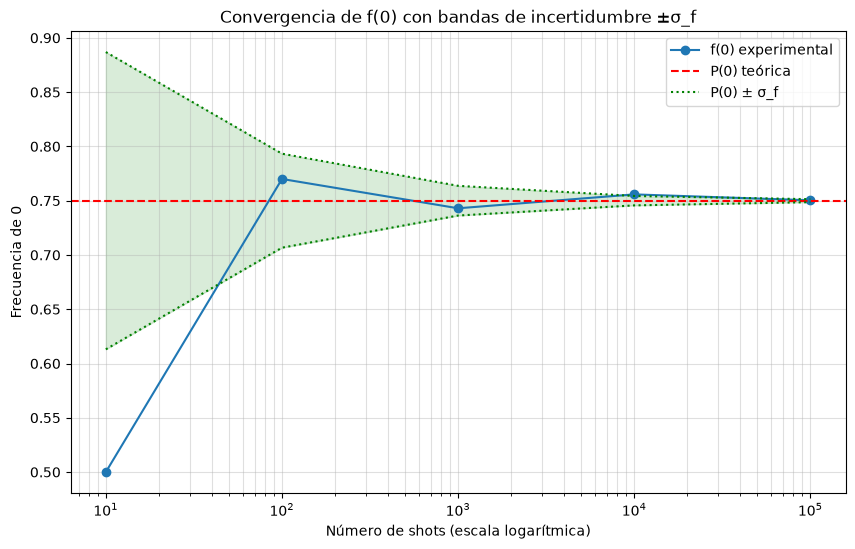

In [135]:
p = calcular_probabilidades(psi_2)[0]          
N = np.array(shots_estudiados)
sigma_f = np.sqrt(p * (1 - p) / N)

print(f"Probabilidad teórica de 0: {p:.2f}")
print(f"{'N':>8} | {'sigma_f':>8} | {'p-sigma':>7} | {'p+sigma':>7}")
for n, s in zip(N, sigma_f):
    print(f"{n:>8} | {s:8.5f} | {p-s:7.4f} | {p+s:7.4f}")

plt.figure(figsize=(10, 6))
plt.plot(shots, frecuencias_0, "o-", label="f(0) experimental")
plt.axhline(p, color="r", linestyle="--", label="P(0) teórica")
plt.plot(N, p + sigma_f, "g:", label="P(0) ± σ_f")
plt.plot(N, p - sigma_f, "g:")
plt.fill_between(N, p - sigma_f, p + sigma_f, color="g", alpha=0.15)
plt.xscale("log")
plt.xlabel("Número de shots (escala logarítmica)")
plt.ylabel("Frecuencia de 0")
plt.title("Convergencia de f(0) con bandas de incertidumbre ±σ_f")
plt.grid(True, which="both", alpha=0.4)
plt.legend()
plt.show()

**Responde:** ¿Cómo varía la incertidumbre con $N$? ¿Cuántos shots hacen falta aproximadamente para reducirla a la mitad? ¿Por qué aumentar shots presenta rendimiento decreciente?

**Respuesta:** 
Por cada n+ 1 en $10^n$, la incertidumbre decrece un $10^{n-1}$, hay que cuadruplicar el número de shots para que se reduzca a la mitas, por lo que en verdad decrece en una proporción de $1/\sqrt{4N}$. EL rendimiento es decreciente porque al añadir chots se aumenta la precisión. 

## Pruebas mínimas

Ejecuta estas pruebas después de completar las funciones y añade las necesarias para comprobar entradas no válidas.

In [136]:
# Descomenta cuando hayas implementado las funciones.

assert es_estado_valido([1, 0])[0]
assert es_estado_valido([0, 1])[0]
assert not es_estado_valido([1, 1])[0]
assert not es_estado_valido([0, 0])[0]
assert not es_estado_valido([1, 0, 0])[0]
assert np.isclose(np.linalg.norm(normalizar_estado([1, 1])), 1.0)
assert np.isclose(sum(calcular_probabilidades(psi_2).values()), 1.0)
assert medir(psi_1, np.random.default_rng(42)) in (0, 1)
assert sum(medir_repetidamente(psi_2, 1000, 42).values()) == 1000

# TODO: añade pruebas de excepciones y otros casos límite
def lanza(excepcion, funcion, *args, **kwargs):
    """True si la llamada lanza la excepción indicada."""
    try:
        funcion(*args, **kwargs)
    except excepcion:
        return True
    return False


# Entradas no válidas y casos límite
assert not es_estado_valido([np.nan, 0])[0]
assert not es_estado_valido([np.inf, 0])[0]
assert lanza(ValueError, normalizar_estado, [0, 0])
assert lanza(ValueError, normalizar_estado, [1, 0, 0])
assert lanza(ValueError, normalizar_estado, [np.inf, 1])
assert lanza(ValueError, calcular_probabilidades, [1, 1])
assert lanza(ValueError, medir, [0, 0])
assert lanza(ValueError, medir_repetidamente, psi_2, 0)
assert lanza(ValueError, medir_repetidamente, psi_2, -5)
assert lanza(ValueError, medir_repetidamente, psi_2, 10.5)
assert lanza(ValueError, crear_estado, 0, 0)
assert lanza(ValueError, crear_estado, np.nan, 1)

# Comportamiento esperado
assert medir(ket_0) == 0 and medir(ket_1) == 1        # estados de la base: resultado determinista
assert np.isclose(calcular_probabilidades(psi_4)[0], 0.5)
assert calcular_probabilidades(-psi_1) == calcular_probabilidades(psi_1)   # fase global
assert medir_repetidamente(psi_2, 500, 7) == medir_repetidamente(psi_2, 500, 7)  # reproducible

print("Todas las pruebas superadas.")


Todas las pruebas superadas.


## Conclusiones

Redacta un máximo de 200 palabras respondiendo:

1. ¿Qué diferencia existe entre amplitud y probabilidad?

    _La amplitud es un número complejo que define el módulo y la fase. La probabilidad es su módulo al cuadrado, es real y no negativo._
2. ¿Qué relación existe entre shots, frecuencias y probabilidades?

    _La probabilidad es el valor auténtico sabiendo el estado, lo que pasa es que al medir el qubit solo sabemos la solución final y no la probabilidad de que sea uno u otro. Por lo que hay que repretir el especimento n veces (shots) para poder ver la proporción en la que se distribuye los n qubit iguales. La frecuencia es esa proporción que se intenta aproximar a la probabilidad._
3. ¿Por qué una sola medida no permite reconstruir el estado?

    _Una sola medida colapsa el estado sin dejar ver lo que había antes de la medida._
4. ¿Por qué dos estados diferentes pueden producir el mismo histograma?

    _Por que el resultado que sale no exxpresa la autentica forma del estado, no se muestra ni la fase ni su parte imaginaria_
5. ¿Qué diferencia conceptual existe entre una superposición y una mezcla clásica?

    _Una mezcla clásica es el desconocimiento del resultado pero ya está definido el sistema. La superposicion en un estado, el sistema está en un único estado bien definido, cuyas amplitudes mantienen una fase entre sí. Esa fase permite que las amplitudes se refuercen o se cancelen (interferencia), algo imposible en una mezcla._

**Conclusión:** 

## Lista de comprobación antes de entregar

- [ ] Todas las celdas se ejecutan en orden sin errores.
- [ ] No quedan bloques `TODO` sin completar.
- [ ] Las probabilidades suman uno.
- [ ] Las gráficas tienen títulos, etiquetas y leyendas.
- [ ] Las respuestas justifican los resultados.
- [ ] Las pruebas mínimas se ejecutan correctamente.
- [ ] El notebook conserva las salidas antes de la entrega.